In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from Bio import SeqIO
import pandas as pd

In [ ]:
#First read in the MCTE info file and save the true transposon classes in a dictionary
True_TE = {}
with open("MCTE_Info.tsv", "r") as MCTE: 
    MCTE.readline()
    for line in MCTE:
        l = line.strip().split()
        if l[5] == "RNA":
            Class = [1]
        elif l[5] == "DNA":
            Class =[2]
        else:
            print(l[5])
        True_TE[l[0]]=Class

In [ ]:
#First read in the MCTE info and save the true transposon classes in a dictionary
True_TE = {}
with open("MCTE_Info.tsv", "r") as MCTE:
    MCTE.readline()
    for line in MCTE:
        l = line.strip().split()
        if l[5] == "RNA":
            Class = ["1"]
        elif l[5] == "DNA":
            Class =["2"]
        else:
            print(l[5])
        True_TE[l[0]]=Class

#Now read in all the classifications from the three tools (TU, RC, DT)

#TransposonUltimate (RFSB Clasifier)
with open("MCTE_RFSB_results.txt", "r") as TU:
    for line in TU:
        if not line.strip() or line.startswith("#"):
            continue
        if line.startswith(">"):
            TE = line[1:].strip()
            TE =TE.replace("DBGP", "BDGP") #This is necessary because of a typo in the MCTE info file  :)
        else:
            Class = line.split()[1].split("/")[0]
            True_TE[TE].append(Class)

df = (
    pd.DataFrame.from_dict(
        True_TE,
        orient='index',
        columns=['MCTE', 'ComparisonLib']
    )
    .reset_index(names='id')
)

df["Classification:MCTE_OtherTool"] = df["MCTE"] +"_" + df["ComparisonLib"]   
df["Tool"] = "TransposonUltimate (RFSB)"

In [ ]:
#Same thing but not for DeepTE

#First read in MCTE to get the classes
True_TE = {}
with open("MCTE_Info.tsv", "r") as MCTE:
    MCTE.readline()
    for line in MCTE:
        l = line.strip().split()
        if l[5] == "RNA":
            Class = ["1"]
        elif l[5] == "DNA":
            Class =["2"]
        else:
            print(l[5])
        True_TE[l[0]]=Class

#DeepTE
#Now map the deepTE results to it
deepTE = "opt_DeepTE.txt"
with open(deepTE, "r") as DT:
    for line in DT:
        l = line.strip().split()
        TE = l[0]
        TE =TE.replace("DBGP", "BDGP") #again deal with typo in info file
        Class = l[1].split("_")[0]
        if Class == "ClassI":
            Class = "1"
        elif Class == "ClassII":
            Class = "2"
        elif Class == "ClassIII":
            Class = "2"
        elif Class == "unknown":
            Class = "Unknown/Other"
        True_TE[TE].append(Class)

#Save in a new df
df2 = (
    pd.DataFrame.from_dict(
        True_TE,
        orient='index',
        columns=['MCTE', 'ComparisonLib']
    )
    .reset_index(names='id')
)

df2["Classification:MCTE_OtherTool"] = df2["MCTE"] +"_" + df2["ComparisonLib"]   
df2["Tool"] = "DeepTE"

In [ ]:
#Finally for repeatclassifier
#First read in the MCTE info and save the true transposon classes in a dictionary
True_TE = {}
with open("MCTE_Info.tsv", "r") as MCTE:
    MCTE.readline()
    for line in MCTE:
        l = line.strip().split()
        if l[5] == "RNA":
            Class = ["1"]
        elif l[5] == "DNA":
            Class =["2"]
        else:
            print(l[5])
        True_TE[l[0]]=Class

#Repeat Classifier
RC = SeqIO.to_dict(SeqIO.parse("MCTE_RechEtAl22.fasta.classified", "fasta"))#again this is fasta 

for key in RC:
    TE = key.split("#")[0]
    TE =TE.replace("DBGP", "BDGP")#typo again :D
    Class = key.split("#")[1].split()[0].split("/")[0]
    if Class == "LTR" or Class == "LINE" or Class == "SINE":
        Class = "1"
    elif Class == "DNA" or Class == "RC":
        Class = "2"
    elif Class == "Simple_repeat" or Class == "Low_Complexity" or Class == "Satellite" or Class == "rRNA" or Class == "tRNA":
        Class = "Unknown/Other"
    elif Class == "Unknown":
        Class = "Unknown/Other"
    else:
        print(Class)
    True_TE[TE].append(Class)

#Finally the third df 
df3 = (
    pd.DataFrame.from_dict(
        True_TE,
        orient='index',
        columns=['MCTE', 'ComparisonLib']
    )
    .reset_index(names='id')
)

df3["Classification:MCTE_OtherTool"] = df3["MCTE"] +"_" + df3["ComparisonLib"]   
df3["Tool"] = "RepeatClassifier"


In [ ]:
#Merge all into one df. 
final = pd.concat([df,df2,df3])

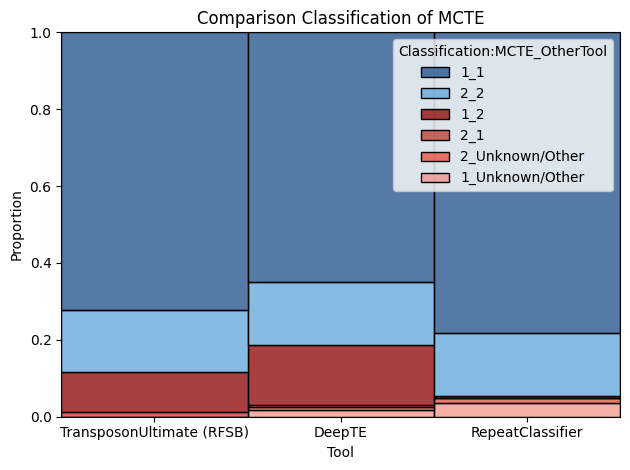

In [ ]:
#Now plot the results
palette = [
    "#1D4E89",  
    "#5DA5DA",  
    "#8B0000",  
    "#C0392B",  
    "#E74C3C",  
    "#F1948A",  
]
sns.histplot(data=final,x="Tool",hue = "Classification:MCTE_OtherTool", stat = "count", multiple = "fill", palette = palette)
plt.ylabel("Proportion")
plt.title("Comparison Classification of MCTE")
plt.tight_layout()
plt.savefig("ClassifyMCTE.jpg") #and now thats it